# Stateful Python Code Completion

**Pilot notebook prepared; execution remains an owner action.** This profile selects 5,000 training files, a fixed 1,000-file validation subset and at most 15 epochs, with early stopping allowed only after epoch 5. The test partition is unchanged. The existing 20,000-file preparation and its tokenizer/encoded caches remain preserved; executing this notebook creates separate immutable pilot artifacts. No pilot data preparation or training has run as part of this update. The selected execution settings are recorded in `../docs/performance_tuning.md`.

Select **Stateful Code Completion — Python 3.13**. Execute the numbered actions in order, reading each result. This notebook imports ordinary modules under `src/`; it contains no training or service implementation. Start with `RUN_NAME = None` for a fresh pilot run that snapshots configuration, source and environment. Never edit them mid-run; explicitly create a new run for a different configuration. Dataset acquisition is an explicit action below and reuses only verified local artifacts when available.

The scientific question compares last-window recomputation, exact prefix reuse and approximate sink-plus-recent caching. Prediction quality is not functional correctness; generated code is never executed. All budgets include sink tokens. Inspect negative results and failed gates without relaxing them.

Direct model checks precede service startup so there is one accelerator owner. Stop the API before any training, evaluation or direct-engine work. Source text is authoritative; proposals are private branches until explicitly accepted.


### 1. Import project modules

Imports define functions only; they do not acquire data, allocate runs, construct models or start workers. Run this notebook from the project root or its notebooks directory.


In [1]:
from pathlib import Path
import json
import sys
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
assert (PROJECT_ROOT / "src" / "config.py").is_file(), "Open Jupyter from this project"
sys.path.insert(0, str(PROJECT_ROOT)) if str(PROJECT_ROOT) not in sys.path else None
from src.config import DataConfig, ModelConfig, TrainingConfig, ServiceConfig, ExperimentConfig
from src.bootstrap import configure_environment


### 2. Define data configuration

The pilot explicitly selects 5,000 training files after eligibility, deduplication and repository/clone-group splitting, plus a fixed deterministic 1,000-file subset of the validation pool. The test partition stays unchanged. These limits create a distinct preparation identity when executed; they do not overwrite the existing 20,000-file cache. Insufficient eligible counts stop preparation.


In [2]:
data_config = DataConfig(training_files=5000, validation_files=1000)


### 3. Define model configuration

8192-token vocabulary; 8 blocks, width512, 8 heads, FF1536, 1024 context, FP32. Architecture and instantiated count are saved during training.


In [3]:
model_config = ModelConfig()


### 4. Define training configuration

The pilot has a maximum of 15 epochs, with validation early stopping allowed only after epoch 5 and patience 3. Its warmup/cosine update budget is planned over 15 epochs. Keep the selected execution settings: training batch size 4 with 8 accumulation steps, validation batch size 16, six CPU threads, zero DataLoader workers and Metal preference enabled. Effective batch remains 32 windows per update; seed 42 and fixed AdamW are unchanged. Selection came from short screening logs, not a completed full-epoch speedup comparison.


In [4]:
training_config = TrainingConfig(max_epochs=15)


### 5. Define cache and service configuration

MPS → CUDA → CPU is selected explicitly. Cache budgets256/512/1024 include all retained positions. Localhost, 4 sessions, queue8, 120-second deadline.


In [5]:
service_config = ServiceConfig()


### 6. Assemble the experiment configuration

This only assembles settings; no run is created.


In [6]:
experiment_config = ExperimentConfig(data=data_config, model=model_config, training=training_config, service=service_config)


### 7. Select fresh run or explicit resume

Keep None to create a fresh pilot run. Do not reuse the earlier 20,000-file trial for this different data/schedule profile. To resume a later compatible pilot run, set its exact name; its saved settings take precedence.


In [7]:
RUN_NAME = None


### 8. Resolve execution settings before importing PyTorch

Opening a run reads its saved configuration before selecting kernels and CPU threads; fresh runs use the configuration defined above.


In [8]:
effective_config = experiment_config if RUN_NAME is None else ExperimentConfig.from_dict(json.loads((PROJECT_ROOT / "runs" / RUN_NAME / "config" / "experiment.json").read_text()))


### 9. Configure MPS before importing PyTorch

Fresh runs use the selected Metal preference; resumed runs use their saved preference. Fast math and CPU fallback remain disabled. Restart the kernel to change this setting after importing PyTorch.


In [9]:
configure_environment(effective_config.training.prefer_metal)


{'prefer_metal': True, 'fast_math': False, 'cpu_fallback': False}

### 10. Import the pipeline modules

Imports expose functions only; they do not acquire data or start training. PyTorch is imported only after the execution environment is selected.


In [10]:
from src.runs import create_run, open_run
from src.runtime import configure_execution, inspect_runtime, seed_everything, validate_runtime, run_acceptance_tests, release_resources
from src.data import acquire_data, prepare_data, data_audit, training_eda
from src.tokenizer import train_tokenizer, verify_roundtrips, build_encoded_windows
from src.model import CodeTransformer, inspect_model
from src.train import train_model, training_status
from src.checkpoints import freeze_checkpoint
from src.evaluate import evaluate_model, evaluate_lines, evaluate_streaming, failure_examples
from src.benchmark import prepare_benchmark_panel, check_cache_parity, benchmark_engine, benchmark_http, benchmark_restart
from src.service import start_service, stop_service
from src.client import CompletionClient
from src.plotting import plot_learning_curves, plot_prediction_quality, plot_completion_quality, plot_streaming_quality, plot_engine_latency, plot_http_latency, plot_memory, plot_kv_memory
from src.reporting import generate_report


### 11. Configure CPU execution settings

Fresh defaults use six CPU threads; resumed runs use their saved count. Apply it before model operations and verify the requested MPS kernel preference.


In [11]:
configure_execution(effective_config.training)


{'requested_cpu_threads': 6,
 'actual_cpu_threads': 6,
 'actual_interop_threads': 10,
 'num_workers': 0,
 'worker_cpu_threads': None,
 'validation_batch_size': 16,
 'prefer_metal': True,
 'fast_math': False,
 'cpu_fallback': False}

### 12. Create or reopen the explicitly selected run

RUN_NAME=None creates the next run_XXX without overwriting an earlier run. A supplied run name opens that exact run and verifies its saved identities.


In [12]:
run = create_run(PROJECT_ROOT, effective_config) if RUN_NAME is None else open_run(PROJECT_ROOT, RUN_NAME)


### 13. Inspect the effective saved configuration

These are the settings all later operations use, including when opening an existing run.


In [13]:
run.config.to_dict()


{'data': {'training_files': 5000,
  'validation_files': 1000,
  'seed': 42,
  'vocab_size': 8192,
  'minhash_permutations': 128,
  'shingle_size': 5,
  'clone_threshold': 0.9},
 'model': {'vocab_size': 8192,
  'layers': 8,
  'width': 512,
  'heads': 8,
  'ff_width': 1536,
  'context_length': 1024,
  'dropout': 0.1,
  'norm_eps': 1e-05,
  'rope_base': 10000.0},
 'training': {'seed': 42,
  'max_epochs': 15,
  'min_epochs': 5,
  'patience': 3,
  'min_delta': 0.0001,
  'batch_size': 4,
  'accumulation_steps': 8,
  'learning_rate': 0.0003,
  'min_learning_rate': 3e-05,
  'warmup_fraction': 0.05,
  'betas': (0.9, 0.95),
  'eps': 1e-08,
  'weight_decay': 0.1,
  'gradient_clip': 1.0,
  'checkpoint_interval': 100,
  'validation_batch_size': 16,
  'cpu_threads': 6,
  'num_workers': 0,
  'prefer_metal': True},
 'service': {'budgets': (256, 512, 1024),
  'sink_tokens': 4,
  'max_sessions': 4,
  'queue_size': 8,
  'deadline_seconds': 120.0,
  'max_source_bytes': 1048576,
  'max_new_tokens': 64,
  '

### 14. Inspect the selected runtime

Read the selected backend and available memory counters. This is not a fit or a guarantee that the recipe fits memory.


In [14]:
inspect_runtime(run)


{'device': 'mps',
 'torch': '2.14.0',
 'machine': 'arm64',
 'device_name': 'arm',
 'default_dtype': 'torch.float32',
 'mps_fallback': '0',
 'mps_prefer_metal': '1',
 'mps_fast_math': '0',
 'cpu_threads': 6,
 'interop_threads': 10,
 'cuda_tf32_matmul': False,
 'cudnn_tf32': True,
 'deterministic_algorithms': False,
 'execution': {'requested_cpu_threads': 6,
  'actual_cpu_threads': 6,
  'actual_interop_threads': 10,
  'num_workers': 0,
  'worker_cpu_threads': None,
  'validation_batch_size': 16,
  'prefer_metal': True,
  'fast_math': False,
  'cpu_fallback': False},
 'memory': {'rss_bytes': 355860480,
  'device': 'mps',
  'allocated_bytes': 0,
  'driver_allocated_bytes': 393216,
  'measurement': 'instantaneous; overlapping unified-memory counters must not be summed'}}

### 15. Acquire creator data and pinned manifests

Explicit network action. Downloads the raw-source archive and pinned Py150 Open manifests; records URLs, bytes and SHA256. Reuses only verified local acquisition artifacts.


In [15]:
raw_data = acquire_data(run)


### 16. Prepare eligibility, duplicates and splits

Applies licenses, Python 3.13 parsing, exact/verified-near deduplication and repository/clone grouping. Selects exactly 5,000 training files and the fixed 1,000-file validation subset, leaving the test partition unchanged. Writes a new immutable pilot preparation cache on execution; the earlier 20,000-file cache remains intact. Incompatible code is excluded without translation.


In [16]:
prepared = prepare_data(run)


### 17. Display the data audit

Read exclusions, group distributions, clone edges and file/length counts before proceeding. This is a Py150-derived split, not official benchmark scores.


In [17]:
data_audit(run, prepared)


{'clone_edges': 811,
 'clone_edges_parent_cache_id': '0bf59e5e72e3d42dfba262a3c26f2f169e869e504053c86e3a7d8465b6beafc7',
 'clone_limit': 'Deterministic MinHash candidate retrieval can miss near duplicates; candidates verified with exact Jaccard.',
 'eligible_split_counts': {'test': 15937, 'train': 84812, 'validation': 8768},
 'exclusions': {'encoding_or_python313_parse': 13133,
  'exact_duplicate': 18,
  'license': 1072,
  'near_duplicate': 376,
  'no_lexical_tokens': 392},
 'inherited_global_audit': 'Manifest/eligible counts, exclusions, clone edges and split method are inherited from the verified full parent; no parsing or clone detection was repeated.',
 'manifest_files': 124508,
 'parent_available_counts': {'test': 15937,
  'train': 20000,
  'validation': 8768},
 'parent_identity': {'cache_id': '0bf59e5e72e3d42dfba262a3c26f2f169e869e504053c86e3a7d8465b6beafc7',
  'inventory': '7d15d652a471fe0ce9a8e735d21eb6c25c0920ee825904a6a97de78db42182a3',
  'protocol': 'py150-python313-reposito

### 18. Inspect training-only exploratory analysis

Only selected training records contribute to this exploratory view; held-out results do not influence architecture or recipe.


In [18]:
training_eda(run, prepared)


{'split': 'train',
 'files': 5000,
 'licenses': {'mit': 2040,
  'bsd-3-clause': 1344,
  'apache-2.0': 1269,
  'isc': 36,
  'bsd-2-clause': 309,
  'cc0-1.0': 2},
 'lengths': {'characters': {'min': 10.0,
   'p25': 619.75,
   'median': 1901.5,
   'p75': 4887.0,
   'p95': 18359.150000000005,
   'max': 1420671.0},
  'bytes': {'min': 10.0,
   'p25': 619.75,
   'median': 1901.5,
   'p75': 4887.0,
   'p95': 18359.150000000005,
   'max': 1420671.0},
  'lines': {'min': 1.0,
   'p25': 21.0,
   'median': 59.0,
   'p75': 141.0,
   'p95': 492.15000000000055,
   'max': 17853.0}}}

### 19. Train the byte BPE tokenizer

Fits a separate 8,192-entry byte BPE, including four special tokens, on the newly selected 5,000 training files only. Validation/test text never contributes. Creates a new immutable tokenizer cache when executed and preserves the earlier 20,000-file tokenizer. Indentation, newlines and Unicode bytes are preserved.


In [19]:
tokenizer = train_tokenizer(run, prepared)


### 20. Verify tokenizer round trips

Explicit runtime check of whitespace, Unicode and literal control-token spellings. Read the receipt and stop on failure.


In [20]:
verify_roundtrips(run, prepared, tokenizer)


{'status': 'passed',
 'probes': 132,
 'tokenizer': {'cache_id': '78d0032ae0e50caea5c64b1b7f4185147325a4b088332171fb58d247c0b67263',
  'data': {'cache_id': '8fd43d116d66d7c67547b3ed24f26a970c3c2d74514be1251b563ff0a97171b2',
   'inventory': '61972d361cfe8aa79b1e3a2e91739e5826697ee42efe76edb34cb1e3d0c3ac04',
   'parent': {'cache_id': '0bf59e5e72e3d42dfba262a3c26f2f169e869e504053c86e3a7d8465b6beafc7',
    'inventory': '7d15d652a471fe0ce9a8e735d21eb6c25c0920ee825904a6a97de78db42182a3',
    'protocol': 'py150-python313-repository-clones-v1'},
   'protocol': 'py150-python313-repository-clones-v1'},
  'fit_split': 'train',
  'fitted_file_ids_sha256': 'ea2d35fbaa51b77e456a0ce52cb0e344f8600e78d797a607b6a91894d0e3feec',
  'implementation': {'source_sha256': '6369dc035a2de97317c2d16394370e46e4aad88db92d8c18e2c725abd5f2a402',
   'tokenizers': '0.23.2'},
  'protocol': 'python-byte-bpe-v1',
  'sha256': '6dd342eb6a1ddf9bf523954d320c5e81b41752d123a369485a9cf6c6a173b354',
  'special_ids': {'<|bos|>': 1,

### 21. Build file-local encoded windows

Creates a distinct immutable encoded cache using the pilot preparation and newly fitted tokenizer; earlier 20,000-file encoded artifacts remain preserved. No window crosses a file boundary. PAD targets are ignored; BOS/EOS represent real boundaries; every selected prediction target appears once per epoch.


In [21]:
encoded = build_encoded_windows(run, prepared, tokenizer)


Encode train:   0%|          | 0/5000 [00:00<?, ?it/s]

Encode validation:   0%|          | 0/1000 [00:00<?, ?it/s]

Encode test:   0%|          | 0/15937 [00:00<?, ?it/s]

### 22. Set the inspection seed

Seed42 makes inspection reproducible. A fresh training run independently restores its registered scratch initialization; resume restores committed RNG state.


In [22]:
seed_everything(run.config.training.seed)


### 23. Construct the model

Constructs the explicit PyTorch architecture on CPU for inspection; training selects the registered backend later.


In [23]:
model = CodeTransformer(run.config.model)


### 24. Inspect architecture and parameter count

Default analytical and instantiated parameter counts must be31,465,984. Inspect the tied embedding/output and bias-free layers.


In [24]:
inspect_model(model)


{'architecture': {'vocab_size': 8192,
  'layers': 8,
  'width': 512,
  'heads': 8,
  'ff_width': 1536,
  'context_length': 1024,
  'dropout': 0.1,
  'norm_eps': 1e-05,
  'rope_base': 10000.0},
 'parameters': 31465984,
 'tied_embeddings': True,
 'attention': 'causal MHA with SDPA/reference',
 'cache_keys': 'unrotated',
 'parameter_dtype': 'torch.float32',
 'device': 'cpu',
 'model_repr': 'CodeTransformer(\n  (embedding): Embedding(8192, 512, padding_idx=0)\n  (blocks): ModuleList(\n    (0-7): 8 x TransformerBlock(\n      (attention_norm): RMSNorm()\n      (attention): CausalAttention(\n        (q_proj): Linear(in_features=512, out_features=512, bias=False)\n        (k_proj): Linear(in_features=512, out_features=512, bias=False)\n        (v_proj): Linear(in_features=512, out_features=512, bias=False)\n        (out_proj): Linear(in_features=512, out_features=512, bias=False)\n      )\n      (ff_norm): RMSNorm()\n      (gate_proj): Linear(in_features=512, out_features=1536, bias=False)\n  

### 25. Execute the authored acceptance suite

Executes the authored synthetic acceptance tests for this run in a separate process and saves logs/JUnit/receipt. Investigate failures before scientific execution.


In [25]:
run_acceptance_tests(run)


{'schema': 1,
 'status': 'passed',
 'identity': {'run': {'schema': 1,
   'run': 'run_001',
   'runs_directory': 'runs',
   'config_hash': '85766ce6996d314050eb1a28d42c5ea404c3776d4656897d6979885712945633',
   'source_hash': 'f14ab1aa7b9b9132161ed7c20ef466f88f9e9c2a61bb01839c2a92b42f048c47',
   'environment_hash': 'ddf4858df8d48c18a5353b712480f649ac1164110d31877ebe2ba908d92cafbf',
   'notebook_snapshot_hash': '870274137ffc1302f60c6d753b226fd80fa97df7830346e88ced2a102c3770ee'},
  'interpreter': '/Users/biitu/Documents/Growth/labs/stateful-code-completion/.venv/bin/python'},
 'returncode': 0,
 'counts': {'tests': 194, 'failures': 0, 'errors': 0, 'skipped': 0},
 'console_log': 'logs/acceptance_tests.log',
 'junit': 'environment/acceptance_tests.xml',
 'receipt_hash': '61bc5eae0e28dcace15f27dc0feee100ae771e8b5415438e8c5f7592aebbb873'}

### 26. Execute configured runtime validation

Explicit synthetic forward, reference-attention, incremental-cache, causal and optimizer checks. This gate restores the inspection model and RNG afterward. It does not measure trained quality.


In [26]:
validate_runtime(run, model, encoded)


{'schema': 1,
 'status': 'passed',
 'identity': {'run': {'schema': 1,
   'run': 'run_001',
   'runs_directory': 'runs',
   'config_hash': '85766ce6996d314050eb1a28d42c5ea404c3776d4656897d6979885712945633',
   'source_hash': 'f14ab1aa7b9b9132161ed7c20ef466f88f9e9c2a61bb01839c2a92b42f048c47',
   'environment_hash': 'ddf4858df8d48c18a5353b712480f649ac1164110d31877ebe2ba908d92cafbf',
   'notebook_snapshot_hash': '870274137ffc1302f60c6d753b226fd80fa97df7830346e88ced2a102c3770ee'},
  'encoded': {'protocol': 'file-local-every-target-once-v1',
   'cache_id': 'c869742fd56b0b090a73b2f30cdbd3676f1e932a97d51c4b19a3d5a7e38cb1ce',
   'inventory': '75745a40e249f08222074444b842b26c8ba792fbcf886d5d2375dd58c3bafefb',
   'data': {'protocol': 'py150-python313-repository-clones-v1',
    'cache_id': '8fd43d116d66d7c67547b3ed24f26a970c3c2d74514be1251b563ff0a97171b2',
    'inventory': '61972d361cfe8aa79b1e3a2e91739e5826697ee42efe76edb34cb1e3d0c3ac04',
    'parent': {'protocol': 'py150-python313-repository-clo

### 27. Train or resume

Runs the pilot recipe for at most 15 epochs, with minimum 5 epochs before early stopping and patience 3, using tqdm/TensorBoard and durable update/epoch checkpoints. Reexecuting resumes a compatible pilot committed cursor. Unsupported, nonfinite or memory failures stop and save diagnostics. This action has not been executed for the pilot during preparation.


In [27]:
training_result = train_model(run, encoded, model=model, resume=True)


Epoch 1/15:   0%|          | 0/2726 [00:00<?, ?batch/s]

Full validation:   0%|          | 0/137 [00:00<?, ?it/s]

Epoch 2/15:   0%|          | 0/2726 [00:00<?, ?batch/s]

Full validation:   0%|          | 0/137 [00:00<?, ?it/s]

Epoch 3/15:   0%|          | 0/2726 [00:00<?, ?batch/s]

...

Full validation:   0%|          | 0/137 [00:00<?, ?it/s]

Epoch 11/15:   0%|          | 0/2726 [00:00<?, ?batch/s]

Full validation:   0%|          | 0/137 [00:00<?, ?it/s]

Epoch 12/15:   0%|          | 0/2726 [00:00<?, ?batch/s]

Full validation:   0%|          | 0/137 [00:00<?, ?it/s]

### 28. Inspect training status

Distinguishes last recovery, best validation and final artifacts. Do not infer completion merely from a checkpoint filename.


In [28]:
training_status(run)


{'bad_epochs': 3,
 'best_checkpoint': 'update_00003069_6e09fcdea50d40b4a308d21ab0297fcf.pt',
 'best_epoch': 9,
 'best_validation_nll': 2.1404153043704133,
 'epoch': 12,
 'epoch_loss_sum': 0.0,
 'epoch_target_tokens': 0,
 'epoch_training_seconds': 0.0,
 'next_batch': 0,
 'patience_anchor_nll': 2.1404153043704133,
 'status': 'complete',
 'stop_reason': 'early_stopping',
 'updates': 4092,
 'checkpoint': 'update_00004092_32e28786748944ea9a31f4c7f58346d2.pt',
 'checkpoint_sha256': '68eace9daf52fb366956a73c2f229586bf890d09a6aefc5ddaf00179100a42d3'}

### 29. Plot learning curves

Reads committed epoch rows; no new model execution.


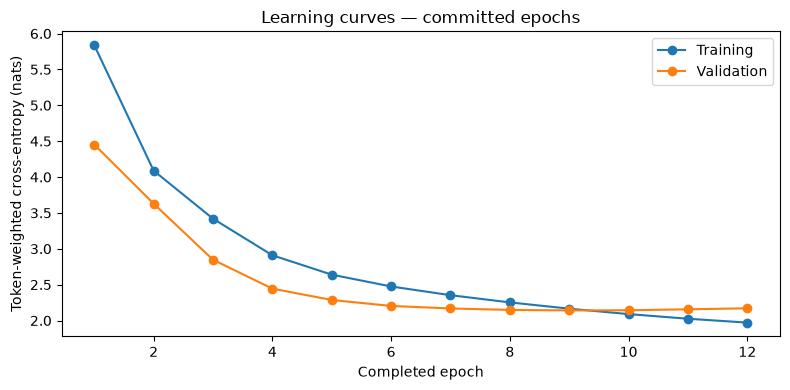

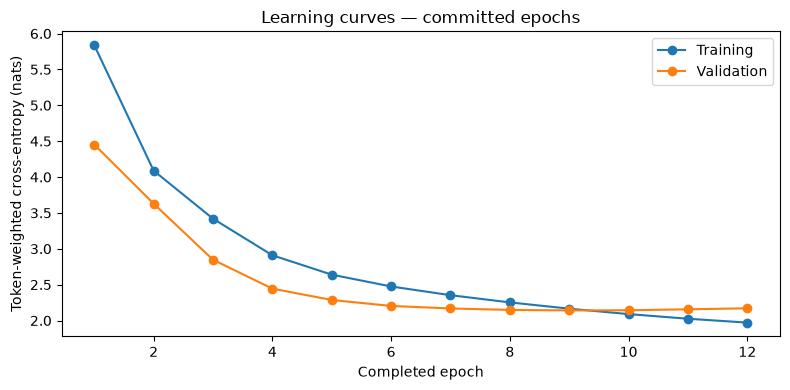

In [29]:
plot_learning_curves(run)


### 30. Drop the notebook model reference

The checkpoint remains on disk. Removing this reference prevents a training model from occupying accelerator memory during independent evaluation/service work.


In [30]:
del model


### 31. Release unused training resources

Collects unreferenced objects and clears available backend caches. No service starts here.


In [31]:
release_resources()


### 32. Freeze the chosen checkpoint and evaluation protocol

Freezes validation-selected inference artifacts and predetermined held-out protocol. This is required before test evaluation.


In [32]:
frozen = freeze_checkpoint(run, encoded)


### 33. Evaluate held-out token prediction

All eligible test windows. Reports token-weighted CE/perplexity/accuracy versus a smoothed training-frequency baseline.


In [33]:
token_results = evaluate_model(run, encoded)


Held-out token prediction:   0%|          | 0/8186 [00:00<?, ?it/s]

### 34. Evaluate next-line completion

Up to 5,000 deterministically selected test cases, at most one per file. Exact text match and edit similarity preserve indentation; compare previous-line copying. Generated code is never executed.


In [34]:
line_results = evaluate_lines(run, encoded)


Select line cases:   0%|          | 0/15937 [00:00<?, ?it/s]

Next-line completion:   0%|          | 0/5000 [00:00<?, ?it/s]

### 35. Evaluate streaming prediction

Up to 128 long files capped at 4,096 tokens; shared scored positions every 32 tokens. Compare all policies and budgets before/after capacity; sink states are approximate.


In [35]:
stream_results = evaluate_streaming(run, encoded)


Cache-quality replay:   0%|          | 0/128 [00:00<?, ?it/s]

### 36. Inspect failure examples

Saved deterministic examples include repetition, EOS/empty/truncation, identifiers and indentation heuristics. They are not functional-correctness verdicts.


In [36]:
failure_examples(run)


[{'id': '30de75338907f25421a22b278505bc6c1804419ccdb4f4ebded2eddaa0ff2f25',
  'line_number': 162,
  'target': '                    state[k][\n',
  'prediction': '',
  'previous_line': '                if vi < nveg:\n',
  'exact_match': 0.0,
  'edit_similarity': 0.0,
  'baseline_exact_match': 0.0,
  'baseline_edit_similarity': 0.6,
  'generated_tokens': 0,
  'stop_reason': 'eos',
  'failures': ['empty_suggestion', 'premature_eos', 'indentation_mismatch']},
 {'id': '72d363f2910a7e901ef70a1ad5f94b4e9716f40310788abeac2d776018139766',
  'line_number': 123,
  'target': '      self.server.get_all_public_ips, self.secret))\n',
  'prediction': '',
  'previous_line': '    return json.loads(self.call(self.MAX_RETRIES,\n',
  'exact_match': 0.0,
  'edit_similarity': 0.0,
  'baseline_exact_match': 0.0,
  'baseline_edit_similarity': 0.1923076923076923,
  'generated_tokens': 0,
  'stop_reason': 'eos',
  'failures': ['empty_suggestion', 'premature_eos', 'indentation_mismatch']},
 {'id': 'e1df2181e6708f

### 37. Freeze the paired validation benchmark panel

Data-selected canonical text/token boundaries support before/at/after capacity workloads. Missing eligible groups remain unavailable.


In [37]:
prepare_benchmark_panel(run, encoded)


{'cases': 36,
 'hash': '1b92f4b3fc6dea8977b7966bd48c052c26e952277b4c318bc8bf1b7487069e1e',
 'unavailable_budgets': [],
 'unavailable_groups': []}

### 38. Check trained-model cache parity

Logits and greedy outputs must satisfy fixed backend tolerances. Sink is compared to its independent token-step reference. Failures are retained; do not relax gates for speed claims.


In [38]:
parity = check_cache_parity(run, encoded)


Trained cache parity:   0%|          | 0/36 [00:00<?, ?it/s]

### 39. Run direct-engine paired benchmarks

Three rotated blocks,20 warm-ups and 100 measured requests per workload. A fixed 32-token continuation isolate equal work; prefill/edit/replay have distinct timing boundaries. No API process may be running.


In [39]:
engine_results = benchmark_engine(run, encoded)


stateless/256/before_capacity/prefill:   0%|          | 0/120 [00:00<?, ?it/s]

stateless/256/before_capacity/fixed_32_tokens:   0%|          | 0/120 [00:00<?, ?it/s]

stateless/256/before_capacity/edit_rebuild:   0%|          | 0/120 [00:00<?, ?it/s]

stateless/256/before_capacity/replay:   0%|          | 0/120 [00:00<?, ?it/s]

stateless/256/at_capacity/prefill:   0%|          | 0/120 [00:00<?, ?it/s]

...

exact/1024/at_capacity/replay:   0%|          | 0/120 [00:00<?, ?it/s]

exact/1024/after_capacity/prefill:   0%|          | 0/120 [00:00<?, ?it/s]

exact/1024/after_capacity/fixed_32_tokens:   0%|          | 0/120 [00:00<?, ?it/s]

exact/1024/after_capacity/edit_rebuild:   0%|          | 0/120 [00:00<?, ?it/s]

exact/1024/after_capacity/replay:   0%|          | 0/120 [00:00<?, ?it/s]

### 40. Release benchmark allocator caches

Direct checks have returned. Clear unreferenced notebook-process allocations before the service child loads its own model.


In [40]:
release_resources()


### 41. Start the local API

Starts one managed child process with the frozen model; health/startup receipts describe the loaded identity. Port defaults to 8000; configuration changes require a fresh run.


In [41]:
service = start_service(run)


### 42. Create the notebook HTTP client

Creates a connection wrapper only; no session yet.


In [42]:
client = CompletionClient(service.url)


### 43. Create a demonstration session

The accepted source starts empty at revision 0. Cache policy and budget are explicit.


In [43]:
session = client.create(policy="exact", budget=1024)


### 44. Set accepted source

Revision-checked whole-prefix replacement; canonical retokenization determines the reusable prefix.


In [44]:
session = client.update_source(session["session_id"], 'def fibonacci(n):\n    if n < 2:\n        return n\n    ', session["revision"])


### 45. Request a streamed suggestion

The client collects JSONL events and returns proposal text, tokens and stop reason. Accepted source stays unchanged.


In [45]:
proposal = client.suggest(session["session_id"], session["revision"])


### 46. Inspect the proposed text

Review text before acceptance. Empty/EOS-only results are noncommittable and remain reportable.


In [46]:
proposal


{'type': 'done',
 'text': '\n',
 'token_ids': [202],
 'stop_reason': 'newline',
 'incomplete_utf8_bytes': 0,
 'session_id': 'bccdfb84104c4f1a8104a91e08a99cee',
 'proposal_id': '6f5f021c10c9461083d2832b4b0e0b63',
 'revision': 1,
 'committable': True,
 'events': [{'type': 'request',
   'request_id': '9efac83715774c31b9d019855f79a98b'},
  {'type': 'token',
   'text': '\n',
   'token_id': 202,
   'index': 0,
   'session_id': 'bccdfb84104c4f1a8104a91e08a99cee',
   'proposal_id': '6f5f021c10c9461083d2832b4b0e0b63',
   'revision': 1},
  {'type': 'done',
   'text': '\n',
   'token_ids': [202],
   'stop_reason': 'newline',
   'incomplete_utf8_bytes': 0,
   'session_id': 'bccdfb84104c4f1a8104a91e08a99cee',
   'proposal_id': '6f5f021c10c9461083d2832b4b0e0b63',
   'revision': 1,
   'committable': True}]}

### 47. Explicitly accept or reject

Default is rejection. To accept after reviewing, replace with `session = client.accept(session["session_id"], proposal["proposal_id"], session["revision"], characters=None)` (or choose a character count). Never accept a stale proposal.


In [47]:
client.reject(session["session_id"], proposal["proposal_id"]) if proposal.get("committable") else {"accepted": False, "reason": proposal["stop_reason"]}


{'session_id': 'bccdfb84104c4f1a8104a91e08a99cee',
 'revision': 1,
 'text': 'def fibonacci(n):\n    if n < 2:\n        return n\n    ',
 'policy': 'exact',
 'budget': 1024,
 'busy': False,
 'proposals': [],
 'cache': {'policy': 'exact',
  'budget': 1024,
  'sink_tokens': 4,
  'canonical_tokens': 20,
  'cache_tokens': 20,
  'current_history_has_evicted': False,
  'cache_bytes': 655360,
  'retained_token_indices': [0,
   1,
   2,
   3,
   4,
   5,
   6,
   7,
   8,
   9,
   10,
   11,
   12,
   13,
   14,
   15,
   16,
   17,
   18,
   19],
  'full_recomputations': 1,
  'canonical_replays': 0,
  'reused_tokens': 1,
  'evictions': 0},
 'identity': {'model': {'architecture': '90cb14277025a55501c448b4464abcedd2e0a7745691304fd589387538cfd8fa',
   'run_identity': {'config_hash': '85766ce6996d314050eb1a28d42c5ea404c3776d4656897d6979885712945633',
    'environment_hash': 'ddf4858df8d48c18a5353b712480f649ac1164110d31877ebe2ba908d92cafbf',
    'notebook_snapshot_hash': '870274137ffc1302f60c6d753b

### 48. Demonstrate prefix-edit invalidation

Changing the function name retokenizes source and invalidates affected states. An intervening edit makes any old proposal stale.


In [48]:
session = client.update_source(session["session_id"], session["text"].replace("fibonacci", "fib"), session["revision"])


### 49. Inspect the edited session

Read revision, accepted text and retained-cache diagnostics.


In [49]:
client.inspect(session["session_id"])


{'session_id': 'bccdfb84104c4f1a8104a91e08a99cee',
 'revision': 2,
 'text': 'def fib(n):\n    if n < 2:\n        return n\n    ',
 'policy': 'exact',
 'budget': 1024,
 'busy': False,
 'proposals': [],
 'cache': {'policy': 'exact',
  'budget': 1024,
  'sink_tokens': 4,
  'canonical_tokens': 17,
  'cache_tokens': 17,
  'current_history_has_evicted': False,
  'cache_bytes': 557056,
  'retained_token_indices': [0,
   1,
   2,
   3,
   4,
   5,
   6,
   7,
   8,
   9,
   10,
   11,
   12,
   13,
   14,
   15,
   16],
  'full_recomputations': 1,
  'canonical_replays': 0,
  'reused_tokens': 5,
  'evictions': 0},
 'identity': {'model': {'architecture': '90cb14277025a55501c448b4464abcedd2e0a7745691304fd589387538cfd8fa',
   'run_identity': {'config_hash': '85766ce6996d314050eb1a28d42c5ea404c3776d4656897d6979885712945633',
    'environment_hash': 'ddf4858df8d48c18a5353b712480f649ac1164110d31877ebe2ba908d92cafbf',
    'notebook_snapshot_hash': '870274137ffc1302f60c6d753b226fd80fa97df7830346e88ced2

### 50. Close the client before restart

This releases HTTP connections only. Accepted source is already atomically saved.


In [50]:
client.close()


### 51. Stop the service for recovery

A real process restart ensures no in-memory KV state survives.


In [51]:
stop_service(service)


{'stopped': True, 'forced': False, 'exitcode': 0}

### 52. Restart the managed service

Loads frozen artifacts in a new worker process; sessions restore explicitly.


In [52]:
service = start_service(run)


### 53. Reconnect the client

Uses the restarted process URL.


In [53]:
client = CompletionClient(service.url)


### 54. Restore accepted source

Validates identities and revision; exact mode reconstructs the retained window and sink mode replays source. Proposals are not persisted.


In [54]:
session = client.restore(session["session_id"])


### 55. Delete the demonstration session

Removes its live state and recovery record after inspection, leaving room for benchmark sessions.


In [55]:
client.delete(session["session_id"])


{'deleted': 'bccdfb84104c4f1a8104a91e08a99cee'}

### 56. Run HTTP and session-lifecycle benchmarks

Paired blocks include natural completions, rejection, partial acceptance and fixed-source edits. Actual output lengths and empty cases are recorded. Source setup is outside completion timing; queueing/tokenization/transfer are inside.


In [56]:
http_results = benchmark_http(run, service)


HTTP stateless/256/before_capacity:   0%|          | 0/120 [00:00<?, ?it/s]

HTTP stateless/256/at_capacity:   0%|          | 0/120 [00:00<?, ?it/s]

HTTP stateless/256/after_capacity:   0%|          | 0/120 [00:00<?, ?it/s]

HTTP stateless/512/before_capacity:   0%|          | 0/120 [00:00<?, ?it/s]

HTTP stateless/512/at_capacity:   0%|          | 0/120 [00:00<?, ?it/s]

...

HTTP exact/512/at_capacity:   0%|          | 0/120 [00:00<?, ?it/s]

HTTP exact/512/after_capacity:   0%|          | 0/120 [00:00<?, ?it/s]

HTTP exact/1024/before_capacity:   0%|          | 0/120 [00:00<?, ?it/s]

HTTP exact/1024/at_capacity:   0%|          | 0/120 [00:00<?, ?it/s]

HTTP exact/1024/after_capacity:   0%|          | 0/120 [00:00<?, ?it/s]

### 57. Close the demonstration client

Benchmark functions manage their own client; close this notebook client before process-lifecycle benchmarks.


In [57]:
client.close()


### 58. Stop the API before lifecycle measurements

Lifecycle measurements start/stop their own managed processes and require the port/accelerator to be free.


In [58]:
stop_service(service)


{'stopped': True, 'forced': False, 'exitcode': 0}

### 59. Measure loading and restart replay

Fresh-process loading/startup and accepted-source replay are reported separately. OS filesystem caches are not cleared. Greedy output must survive restart.


In [59]:
restart_results = benchmark_restart(run)


Restart block 1:   0%|          | 0/120 [00:00<?, ?it/s]

Restart block 2:   0%|          | 0/120 [00:00<?, ?it/s]

Restart block 3:   0%|          | 0/120 [00:00<?, ?it/s]

### 60. Chart token prediction quality

Reads saved scores versus the frequency baseline.


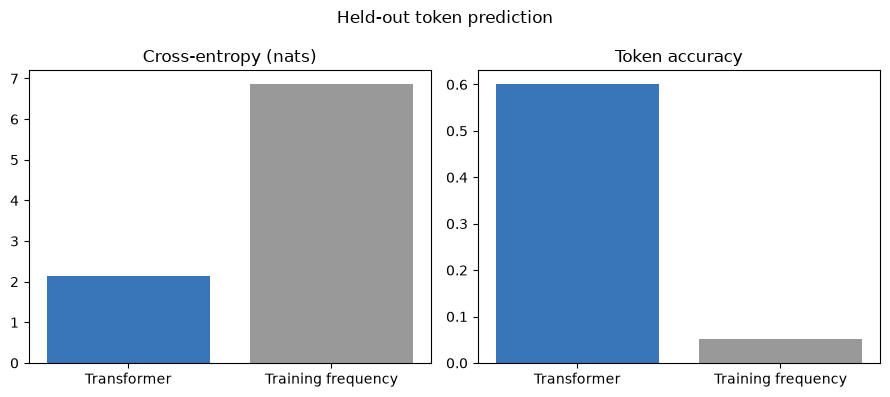

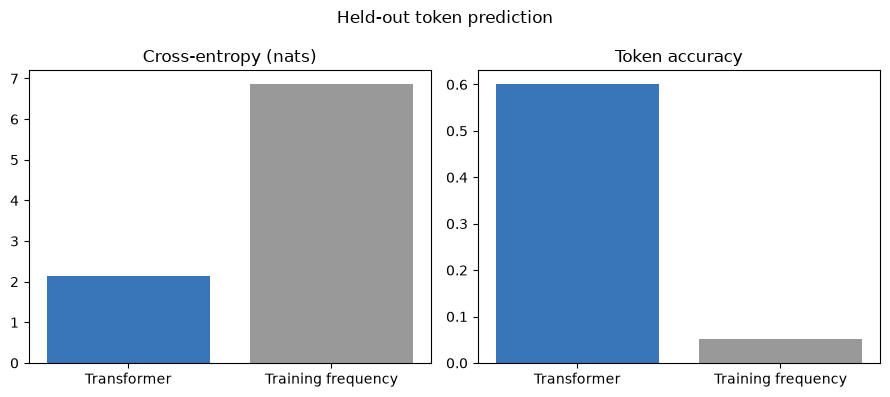

In [60]:
plot_prediction_quality(run)


### 61. Chart next-line quality

Reads exact match and edit similarity versus copying the previous line, with actual case count.


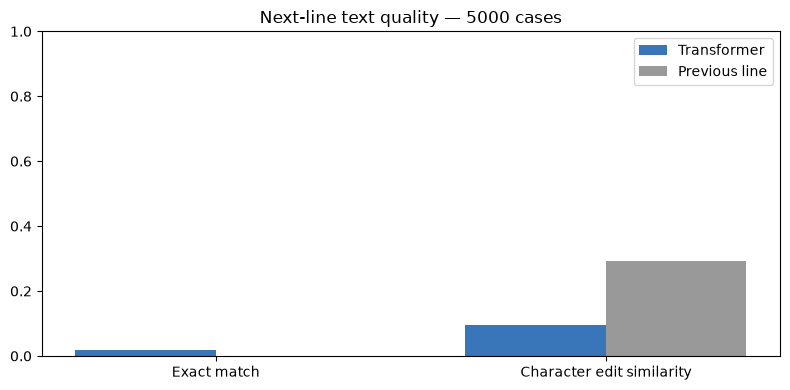

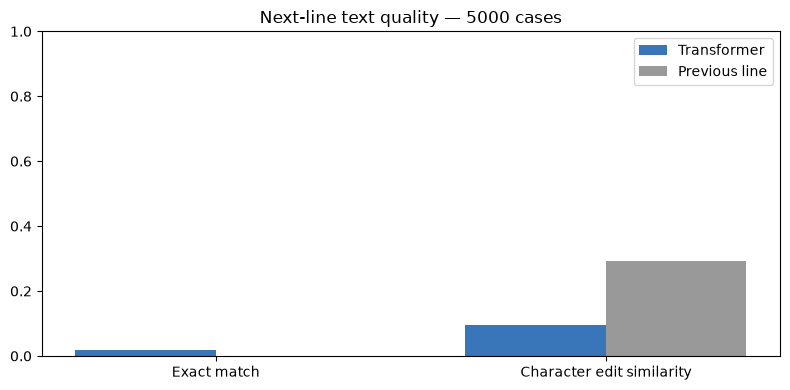

In [61]:
plot_completion_quality(run)


### 62. Chart streaming quality

Separate before/after capacitypanels preserve approximation costs.


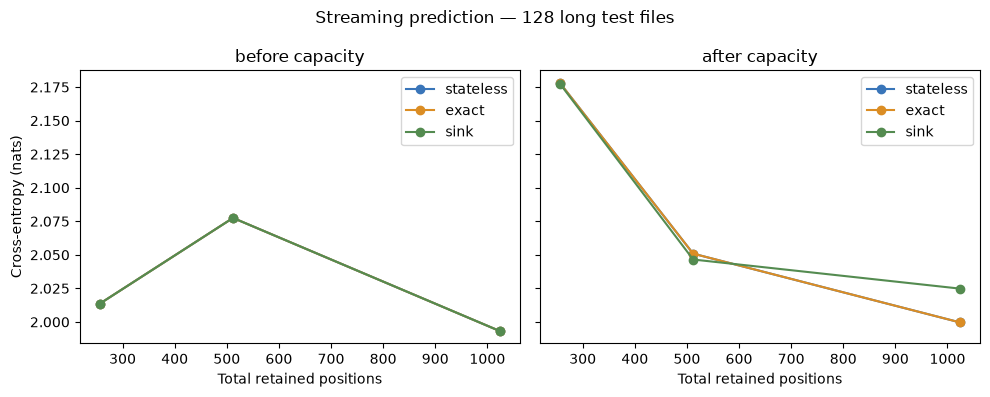

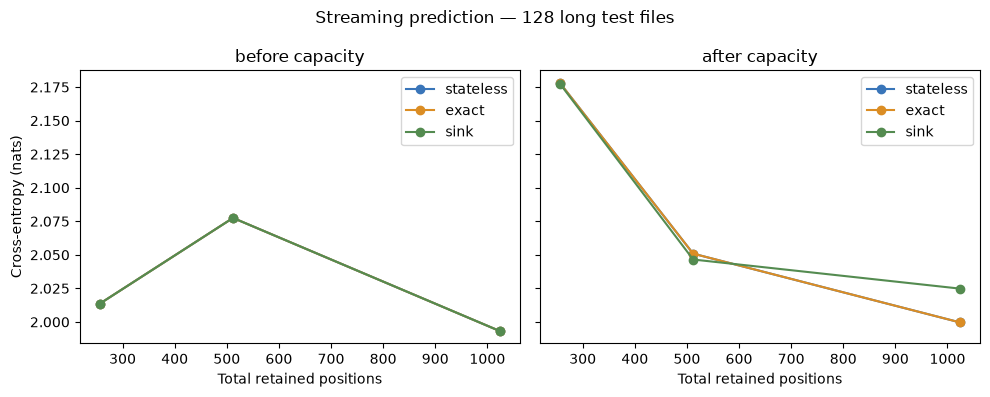

In [62]:
plot_streaming_quality(run)


### 63. Chart direct-engine latency

Each paired block remains visible. Only parity-qualified conditions are plotted; missing conditions are not imputed.


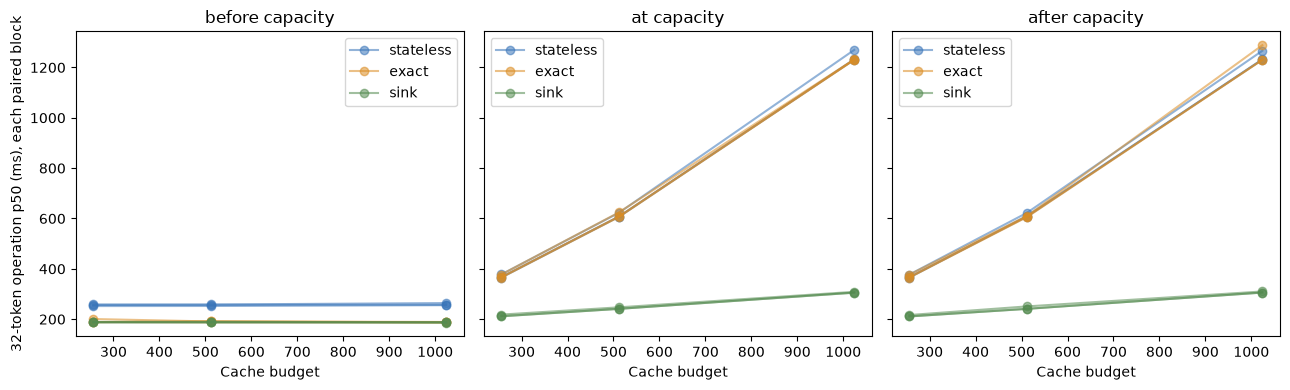

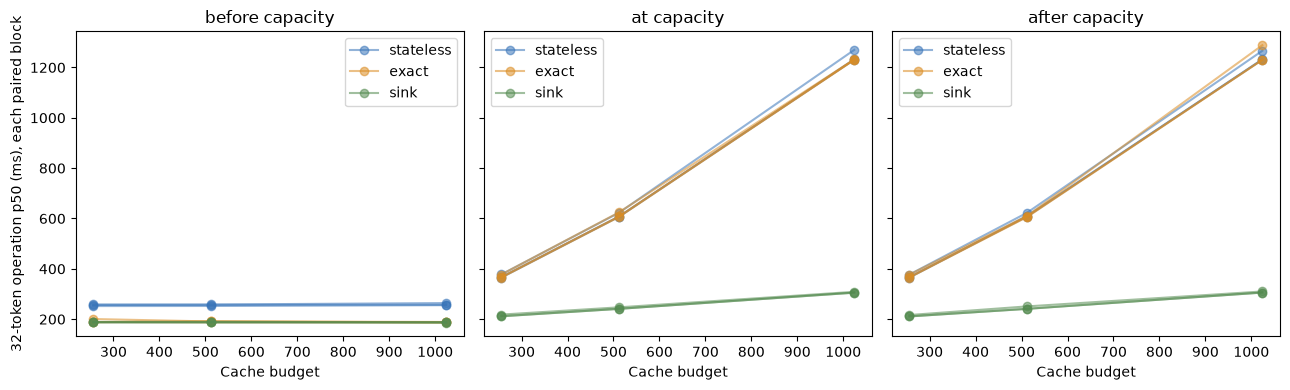

In [63]:
plot_engine_latency(run)


### 64. Chart HTTP latency

Natural output lengths vary; this figure is not an equal-output-work speedup claim.


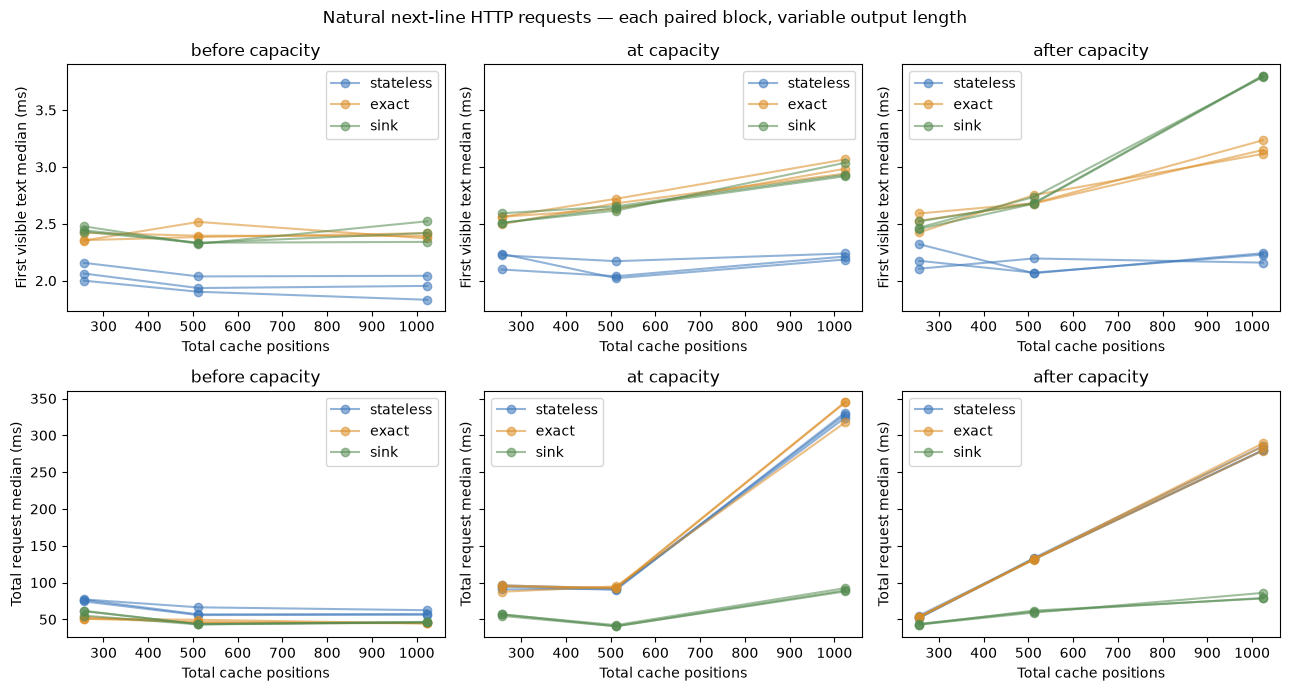

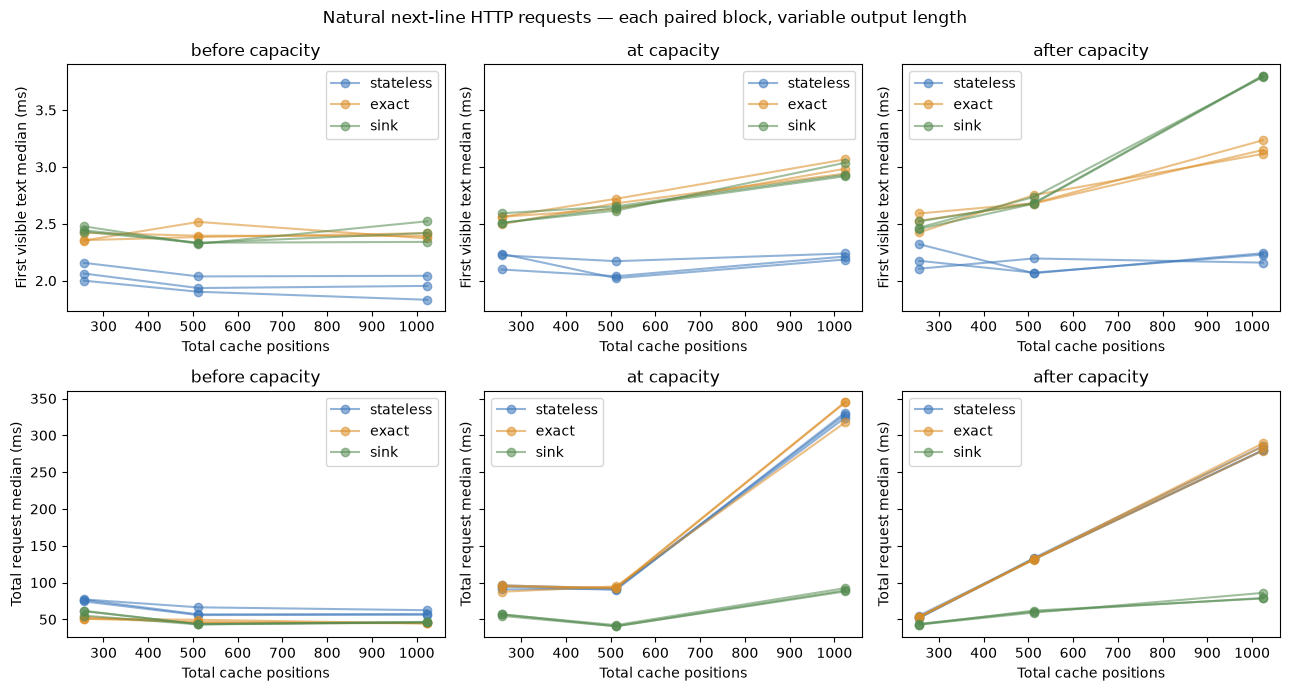

In [64]:
plot_http_latency(run)


### 65. Chart process memory snapshots

Process RSS is separate from per-request KV bytes and device counters in saved rows. These are snapshots, not peak memory.


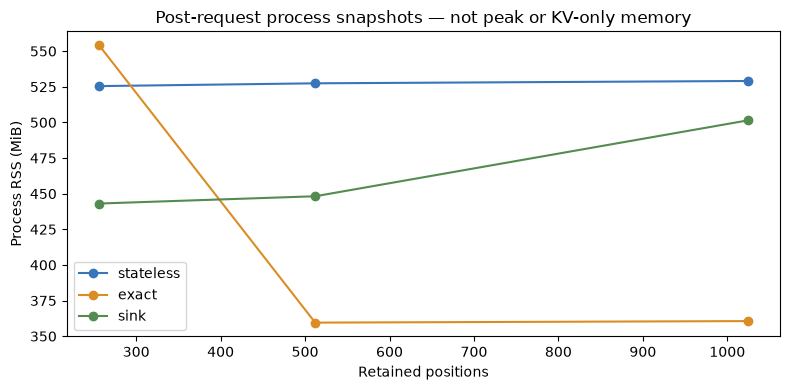

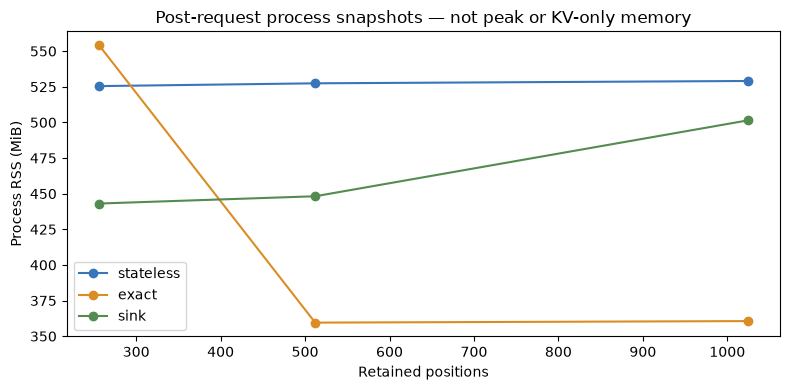

In [65]:
plot_memory(run)


### 66. Chart retained KV tensor memory

Retained tensor bytes exclude source text, private proposals, activations and allocator reserves. Stateless mode retains no reusable KV across requests.


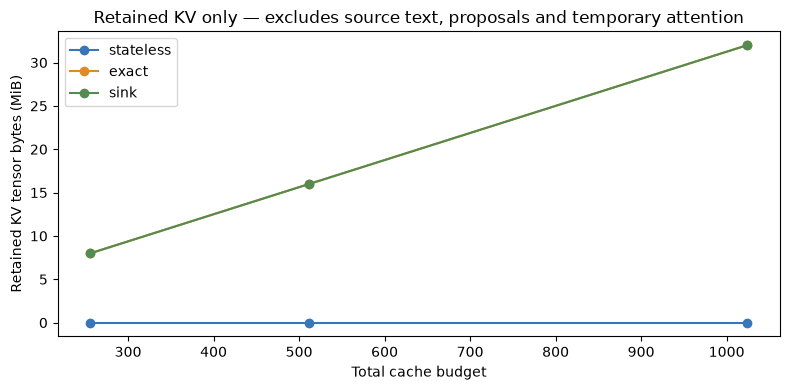

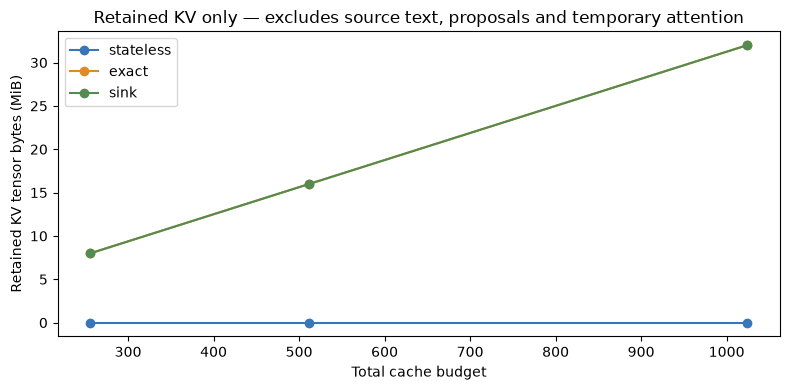

In [66]:
plot_kv_memory(run)


### 67. Assemble the evidence report

Reads saved artifacts, lists missing stages as pending, exports summary tables and checksums. Inspect the actual scientific claims before sharing.


In [67]:
report = generate_report(run)


### 68. Confirm service shutdown

Idempotent final cleanup; lifecycle benchmarking should already have stopped all workers.


In [68]:
stop_service(service)


{'stopped': True, 'forced': False, 'exitcode': 0}

## Execution status

The prepared caches and separate training-speed study do not complete the scientific experiment. Run-specific acceptance/runtime gates, full training, frozen held-out evaluation, trained cache parity and service measurements follow the explicit order above. This notebook itself has no executed cells or saved outputs. See `../docs/HANDOFF.md` for the exact order and `../docs/performance_tuning.md` for measured tuning evidence.
